In [76]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer


wq_df = pd.read_csv("datasets/winequality-red.csv", delimiter=";")
bc_df = pd.read_csv("datasets/Breast-Cancer-Wisconsin-(Diagnostic)-Data-Set.csv")
dataset_names = ["bc", "wq"]
pd.set_option("display.max_rows", 20)
wq_df.tail(10)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1589,6.6,0.725,0.20,7.8,0.073,29.0,79.0,0.99770,3.29,0.54,9.2,5
1590,6.3,0.550,0.15,1.8,0.077,26.0,35.0,0.99314,3.32,0.82,11.6,6
1591,5.4,0.740,0.09,1.7,0.089,16.0,26.0,0.99402,3.67,0.56,11.6,6
1592,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [78]:
bc_df_rounded_example = bc_df.round()
bc_df_rounded_example

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,18.0,10.0,123.0,1001.0,0.0,0.0,0.0,0.0,...,25.0,17.0,185.0,2019.0,0.0,1.0,1.0,0.0,0.0,0.0
1,842517,M,21.0,18.0,133.0,1326.0,0.0,0.0,0.0,0.0,...,25.0,23.0,159.0,1956.0,0.0,0.0,0.0,0.0,0.0,0.0
2,84300903,M,20.0,21.0,130.0,1203.0,0.0,0.0,0.0,0.0,...,24.0,26.0,152.0,1709.0,0.0,0.0,0.0,0.0,0.0,0.0
3,84348301,M,11.0,20.0,78.0,386.0,0.0,0.0,0.0,0.0,...,15.0,26.0,99.0,568.0,0.0,1.0,1.0,0.0,1.0,0.0
4,84358402,M,20.0,14.0,135.0,1297.0,0.0,0.0,0.0,0.0,...,23.0,17.0,152.0,1575.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,22.0,22.0,142.0,1479.0,0.0,0.0,0.0,0.0,...,25.0,26.0,166.0,2027.0,0.0,0.0,0.0,0.0,0.0,0.0
565,926682,M,20.0,28.0,131.0,1261.0,0.0,0.0,0.0,0.0,...,24.0,38.0,155.0,1731.0,0.0,0.0,0.0,0.0,0.0,0.0
566,926954,M,17.0,28.0,108.0,858.0,0.0,0.0,0.0,0.0,...,19.0,34.0,127.0,1124.0,0.0,0.0,0.0,0.0,0.0,0.0
567,927241,M,21.0,29.0,140.0,1265.0,0.0,0.0,0.0,0.0,...,26.0,39.0,185.0,1821.0,0.0,1.0,1.0,0.0,0.0,0.0


In [79]:

y = {"bc": bc_df.loc[:,"diagnosis"], "wq": wq_df.loc[:,"quality"]}
X = {"bc": bc_df.loc[:,"radius_mean":], "wq": wq_df.loc[:,:"alcohol"]}

y["wq"]


0       5
1       5
2       5
3       6
4       5
       ..
1594    5
1595    6
1596    6
1597    5
1598    6
Name: quality, Length: 1599, dtype: int64

In [80]:
def sig_fig_round(num, sig):
    if num==0:
        return 0
    return np.round(num, sig - int(np.floor(np.log10(abs(num)))) - 1)


In [81]:
splits = {}
for name in X:
    X_train, X_test, y_train, y_test = train_test_split(
        X[name], y[name], train_size=0.8, random_state=42
    )
    
    splits[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }
splits["wq"]["y_train"]

493     6
354     6
342     6
834     5
705     5
       ..
1130    6
1294    6
860     5
1459    7
1126    6
Name: quality, Length: 1279, dtype: int64

In [82]:
for i in range(4):
    print(i)

0
1
2
3


In [83]:
models = {"logreg": LogisticRegression(max_iter=10000), "svc": SVC(), "dt":DecisionTreeClassifier(), "knc":KNeighborsClassifier()}
precision_values = {"rounding": [1,2,3,4,5,6], "uniform binning": [2,3,4,5,6], "quantile binning": [2,3,4,5,6], "kmeans binning": [2,3,4,5,6], "sig figs": [1,2,3,4,5,6]}
modes = ["both", "training_data_only", "testing_data_only"]
results = []
# huh = 0
for dataset in dataset_names:
    for model_name, model in models.items():
        base_model = clone(model)

        base_cv_scores = cross_val_score(base_model, splits[dataset]["X_train"], splits[dataset]["y_train"], cv=5)
        base_cv_mean = base_cv_scores.mean()

        base_model.fit(splits[dataset]["X_train"], splits[dataset]["y_train"])
        base_acc = base_model.score(splits[dataset]["X_test"], splits[dataset]["y_test"])
        

        results.append({"dataset": dataset,"method":"base", "model": model_name, "level": 0, "mode": "base", "accuracy": base_acc, "cv": base_cv_mean})

        for method, levels in precision_values.items():
            for level in levels:
                for mode in modes:

                    X_train_new = splits[dataset]["X_train"].copy()
                    X_test_new = splits[dataset]["X_test"].copy()

                    if method == "rounding":
                        if mode == "both":
                            X_train_new = X_train_new.round(level)
                            X_test_new = X_test_new.round(level)
                        elif mode == "training_data_only":
                            X_train_new = X_train_new.round(level)
                        elif mode == "testing_data_only":
                            X_test_new = X_test_new.round(level)

                    elif method == "uniform binning":
                        kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy="uniform")
                        kbd.fit(X_train_new)
                        if mode == "both":
                            X_train_new = pd.DataFrame(kbd.inverse_transform(kbd.transform(X_train_new)))
                            X_test_new  = pd.DataFrame(kbd.inverse_transform(kbd.transform(X_test_new)))
                        elif mode == "training_data_only":
                            X_train_new = pd.DataFrame(kbd.transform(X_train_new), columns=splits[dataset]["X_train"].columns)
                            X_train_new = pd.DataFrame(kbd.inverse_transform(X_train_new), columns=splits[dataset]["X_train"].columns)
                        elif mode == "testing_data_only": 
                            X_test_new = pd.DataFrame(kbd.transform(X_test_new), columns=splits[dataset]["X_test"].columns)
                            X_test_new = pd.DataFrame(kbd.inverse_transform(X_test_new), columns=splits[dataset]["X_test"].columns)
                    
                    elif method == "quantile binning":
                        kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy="quantile")
                        kbd.fit(X_train_new)
                        if mode == "both":
                            X_train_new = kbd.inverse_transform(kbd.transform(X_train_new))
                            X_test_new  = kbd.inverse_transform(kbd.transform(X_test_new)) 
                            
                        elif mode == "training_data_only":
                            X_train_new = pd.DataFrame(kbd.transform(X_train_new), columns=splits[dataset]["X_train"].columns)
                            X_train_new = pd.DataFrame(kbd.inverse_transform(X_train_new), columns=splits[dataset]["X_train"].columns)
                        elif mode == "testing_data_only":
                            X_test_new = pd.DataFrame(kbd.transform(X_test_new), columns=splits[dataset]["X_test"].columns)
                            X_test_new = pd.DataFrame(kbd.inverse_transform(X_test_new), columns=splits[dataset]["X_test"].columns)
                    
                    elif method == "kmeans binning":
                        kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy="kmeans", )
                        kbd.fit(X_train_new)
                        if mode == "both":
                            X_train_new = kbd.inverse_transform(kbd.transform(X_train_new))
                            X_test_new  = kbd.inverse_transform(kbd.transform(X_test_new)) 
                            if level == 2 and model_name == "dt" and dataset == "wq":
                                print(X_train_new)
                        elif mode == "training_data_only":
                            X_train_new = pd.DataFrame(kbd.transform(X_train_new), columns=splits[dataset]["X_train"].columns)
                            X_train_new = pd.DataFrame(kbd.inverse_transform(X_train_new), columns=splits[dataset]["X_train"].columns)
                        elif mode == "testing_data_only":
                            X_test_new = pd.DataFrame(kbd.transform(X_test_new), columns=splits[dataset]["X_test"].columns)
                            X_test_new = pd.DataFrame(kbd.inverse_transform(X_test_new), columns=splits[dataset]["X_test"].columns)
                    
                    elif method == "sig figs":
                        if mode == "both":
                            X_train_new = X_train_new.map(lambda num: sig_fig_round(num, level))
                            X_test_new = X_test_new.map(lambda num: sig_fig_round(num, level))
                        elif mode == "training_data_only":
                            X_train_new = X_train_new.map(lambda num: sig_fig_round(num, level))
                        elif mode == "testing_data_only":
                            X_test_new = X_test_new.map(lambda num: sig_fig_round(num, level))


                    exp_model = clone(model)
                    if mode == "both":
                        cv_scores = cross_val_score(exp_model, X_train_new, splits[dataset]["y_train"], cv=5)
                        cv_mean = cv_scores.mean()
                    else:
                        cv_mean = None
                    
                    exp_model.fit(X_train_new, splits[dataset]["y_train"])

                    exp_acc = exp_model.score(X_test_new, splits[dataset]["y_test"])
                    # if method=="quantile binning" and level==2 and mode == "both":
                    #     huh += 1

                    
                    results.append({"dataset": dataset, "method": method, "model":model_name, "level": level, "mode": mode, "accuracy":exp_acc, "cv":cv_mean})


c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 10000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i

[[ 6.81625459  1.06223904  0.64580368 ...  3.66650876  0.56138311
  12.78225065]
 [ 6.81625459  0.33223904  0.64580368 ...  3.03150876  0.56138311
  12.78225065]
 [12.46625459  0.33223904  0.64580368 ...  3.03150876  0.56138311
   9.53225065]
 ...
 [ 6.81625459  1.06223904  0.14580368 ...  3.66650876  0.56138311
   9.53225065]
 [ 6.81625459  0.33223904  0.64580368 ...  3.03150876  1.37638311
  12.78225065]
 [ 6.81625459  0.33223904  0.14580368 ...  3.66650876  0.56138311
  12.78225065]]


c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans 

In [90]:
pd.set_option("display.max_rows", None)
results = pd.DataFrame(results)
results

,dataset,method,model,level,mode,accuracy,cv
0,bc,base,logreg,0,base,0.956140,0.953846
1,bc,rounding,logreg,1,both,0.956140,0.956044
2,bc,rounding,logreg,1,training_data_only,0.956140,NaN
3,bc,rounding,logreg,1,testing_data_only,0.956140,NaN
4,bc,rounding,logreg,2,both,0.956140,0.953846
5,bc,rounding,logreg,2,training_data_only,0.956140,NaN
6,bc,rounding,logreg,2,testing_data_only,0.956140,NaN
7,bc,rounding,logreg,3,both,0.956140,0.956044
8,bc,rounding,logreg,3,training_data_only,0.956140,NaN
9,bc,rounding,logreg,3,testing_data_only,0.956140,NaN


In [85]:
data = pd.Series([2.3, 5.1, 7.8, 1.2, 9.0, 4.5, 6.7, 3.3])

binned = pd.cut(data, bins=3)

print(binned)

0    (1.192, 3.8]
1      (3.8, 6.4]
2      (6.4, 9.0]
3    (1.192, 3.8]
4      (6.4, 9.0]
5      (3.8, 6.4]
6      (6.4, 9.0]
7    (1.192, 3.8]
dtype: category
Categories (3, interval[float64, right]): [(1.192, 3.8] < (3.8, 6.4] < (6.4, 9.0]]


In [86]:
X_thing = np.array([[2.3],
              [5.1],
              [7.8],
              [1.2],
              [9.0],
              [4.5]])

kbd = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',      
    strategy='uniform'     
)

X_binned = kbd.fit_transform(X_thing)

print("Binned values:")
print(X_binned)

print("Bin edges:")
print(kbd.bin_edges_)
print(kbd.inverse_transform(X_binned))

Binned values:
[[0.]
 [1.]
 [2.]
 [0.]
 [2.]
 [1.]]
Bin edges:
[array([1.2, 3.8, 6.4, 9. ])]
[[2.5]
 [5.1]
 [7.7]
 [2.5]
 [7.7]
 [5.1]]


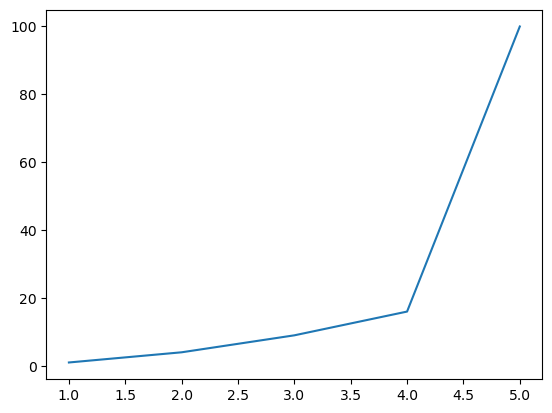

In [87]:
plt.plot([1,2,3,4,5],[1,4,9,16,100])
plt.show()

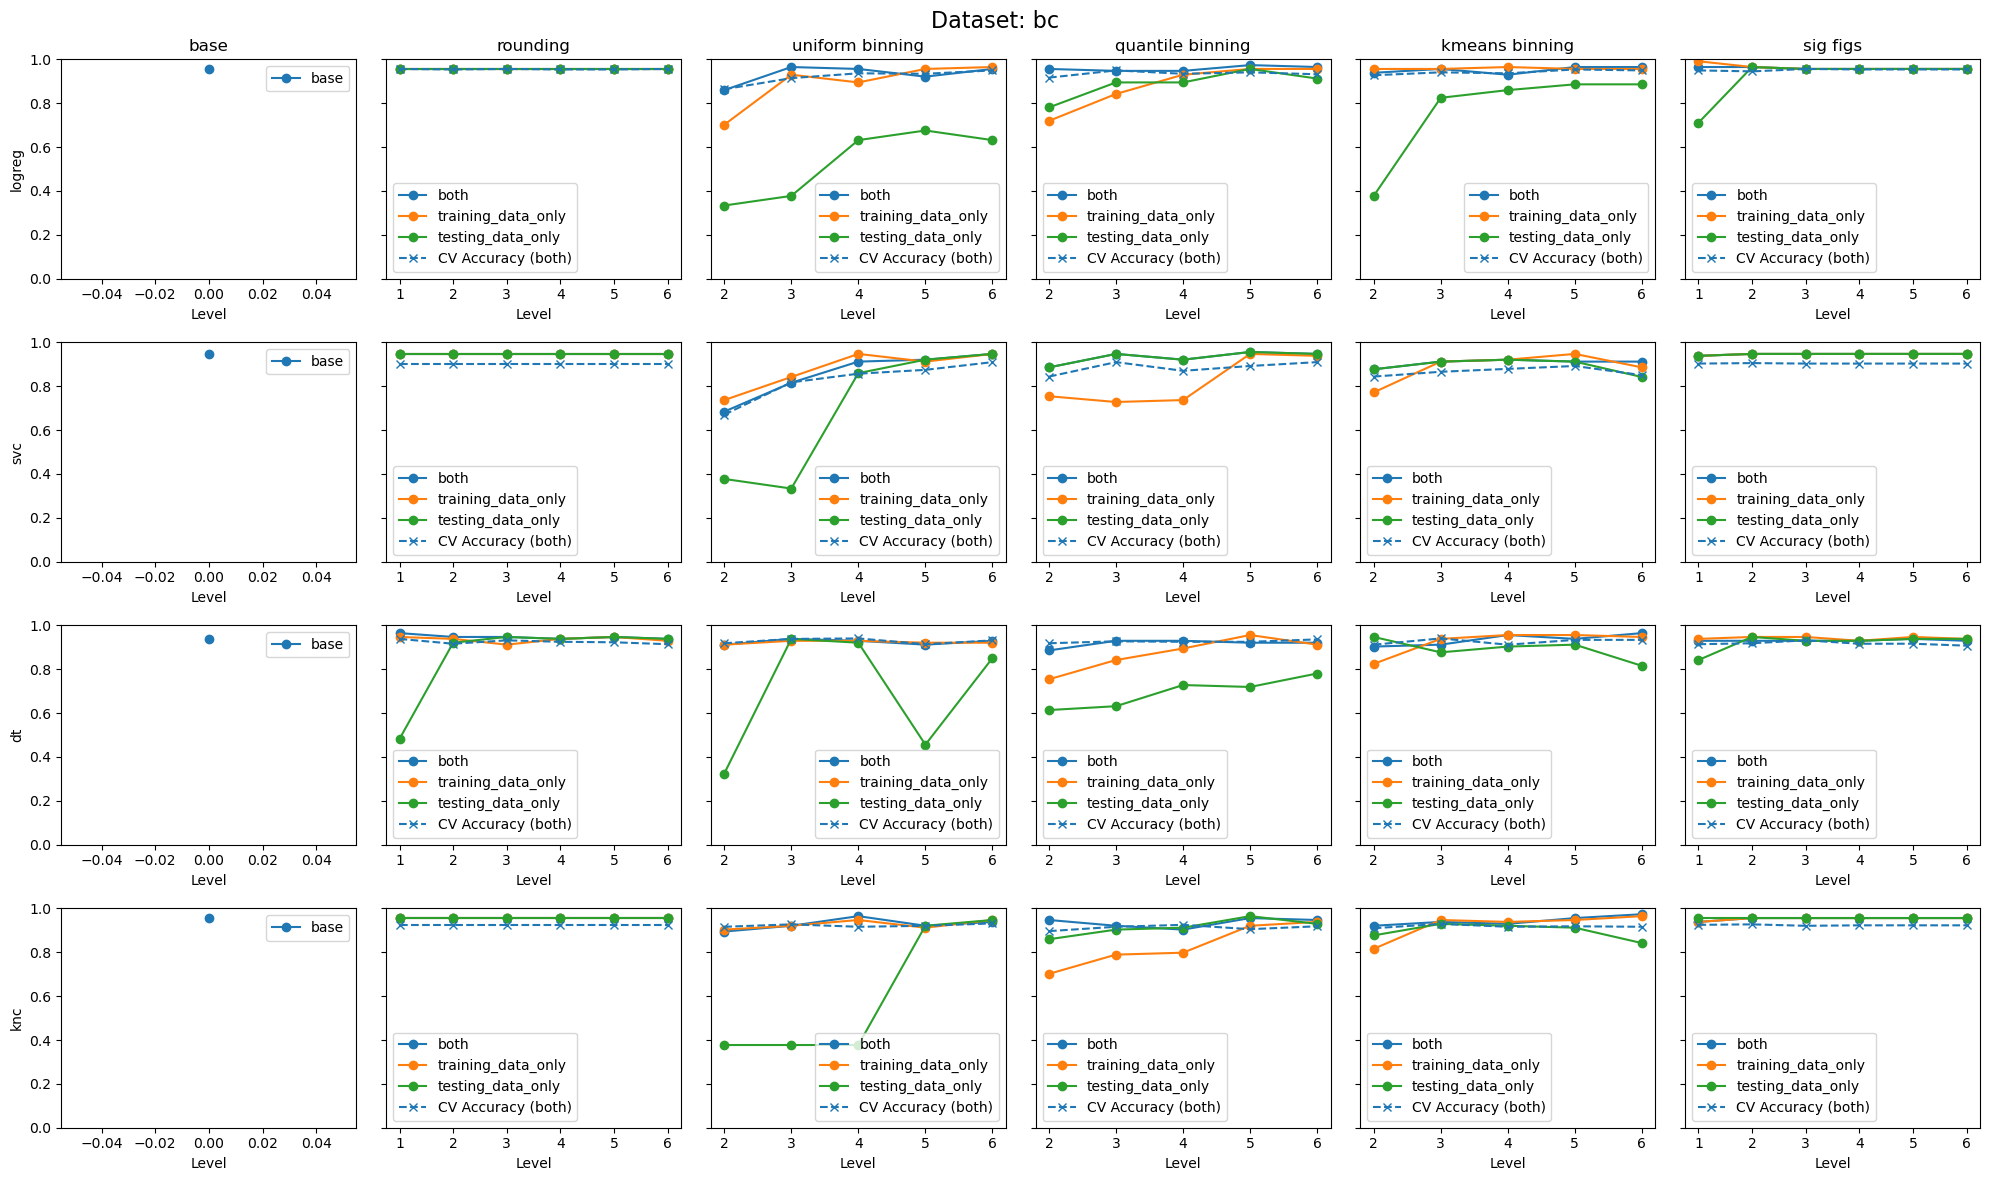

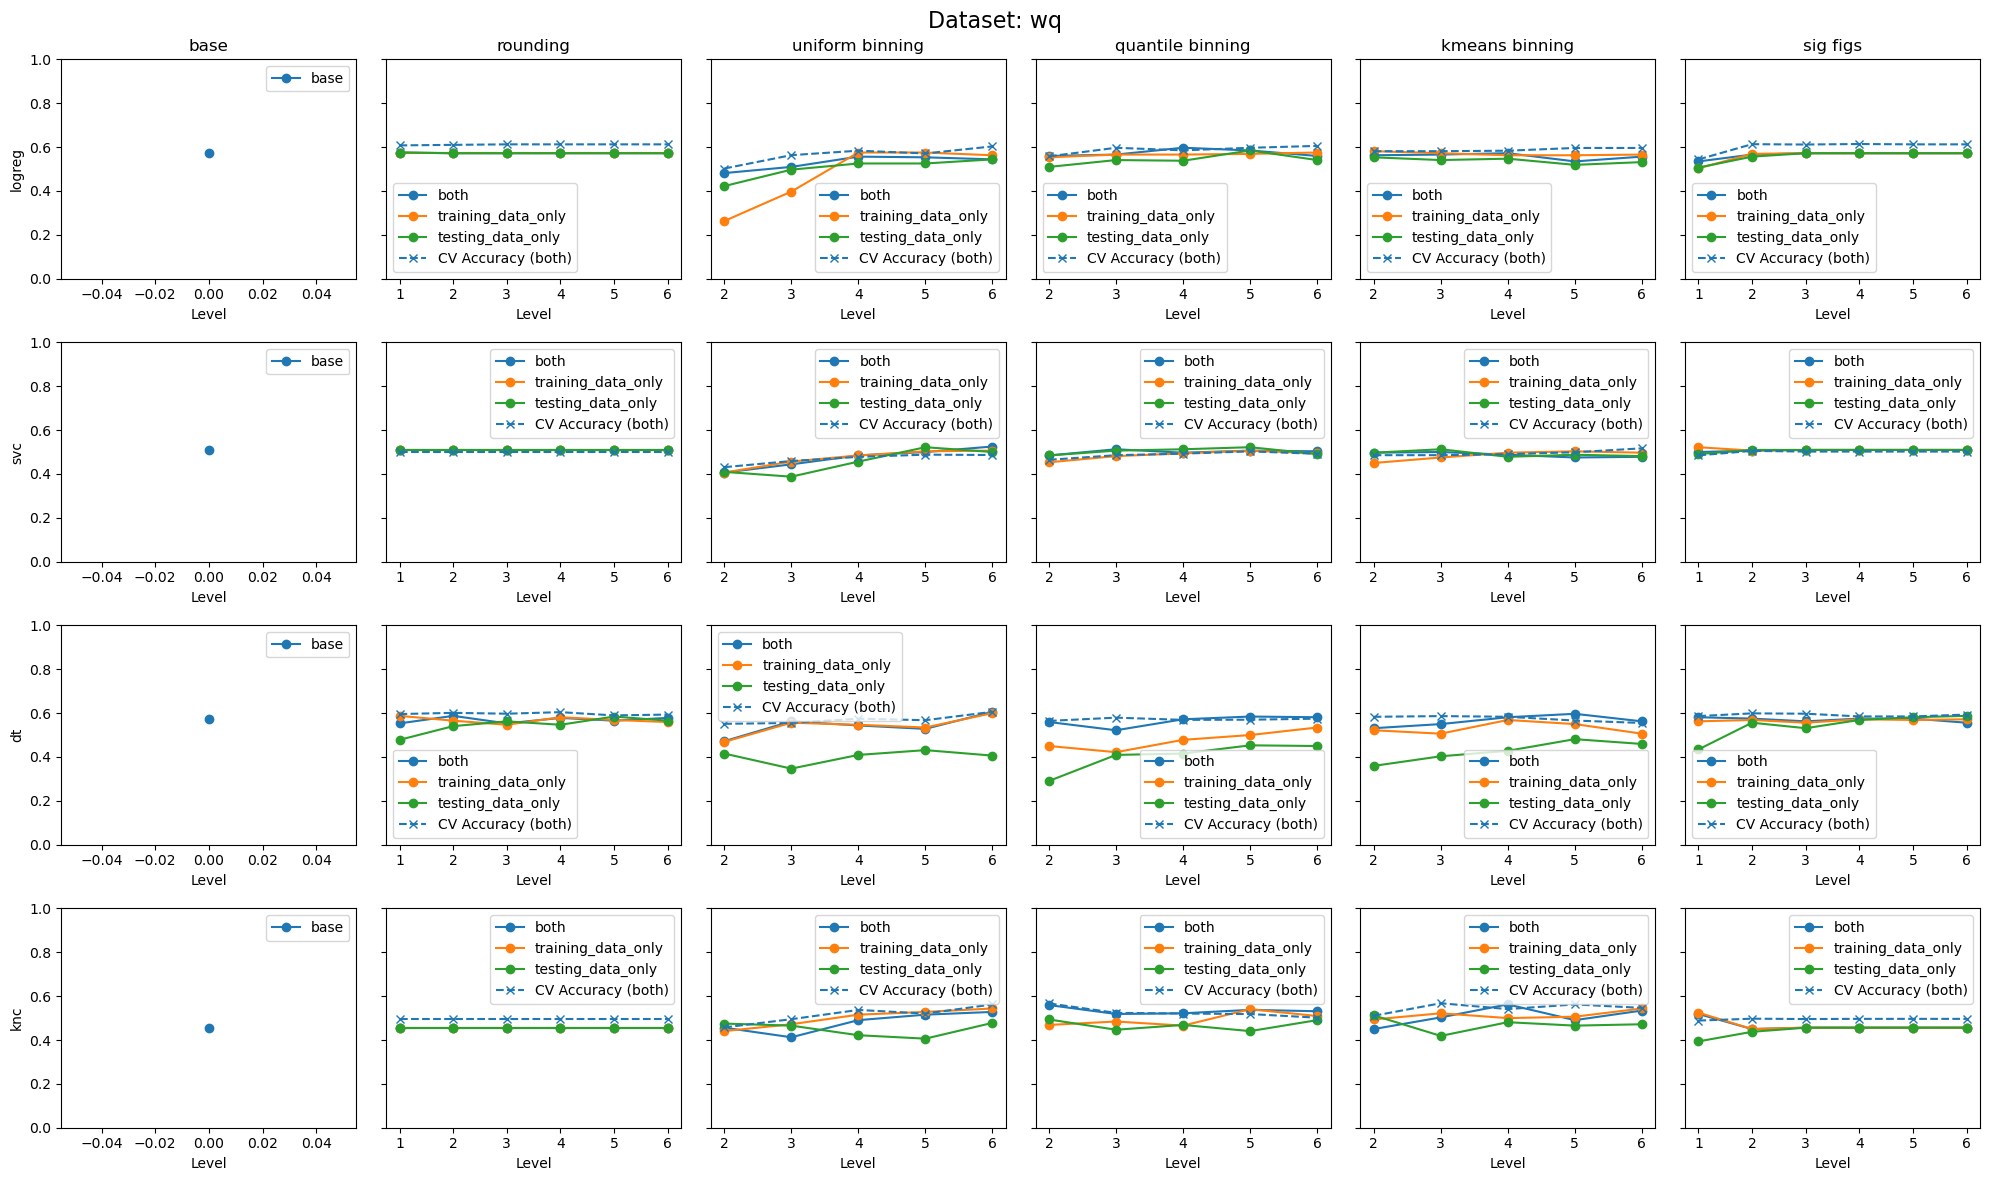

In [91]:
datasets = results['dataset'].unique()
models = results['model'].unique()
methods = results['method'].unique()

for dataset in datasets:

    fig, axes = plt.subplots(len(models), len(methods), figsize=(20, 12), sharey=True)

    for i, model in enumerate(models):
        for j, method in enumerate(methods):

            ax = axes[i, j]

            # subset for this dataset, model, method
            subset = results[
                (results['dataset'] == dataset) &
                (results['model'] == model) &
                (results['method'] == method)
            ]

            # plot accuracy for all modes
            for mode in subset['mode'].unique():
                mode_data = subset[subset['mode'] == mode]
                ax.plot(mode_data['level'], mode_data['accuracy'], marker='o', label=mode)

            # plot CV accuracy for "both" scenario as dotted line
            cv_subset = subset[subset['mode'] == 'both']
            if not cv_subset.empty:
                ax.plot(cv_subset['level'], cv_subset['cv'], linestyle='--', color='tab:blue', marker='x', label='CV Accuracy (both)')

            if i == 0:
                ax.set_title(method)
            if j == 0:
                ax.set_ylabel(model)

            ax.set_xlabel("Level")
            ax.set_ylim(0, 1)
            ax.legend()

    fig.suptitle(f"Dataset: {dataset}", fontsize=16)
    plt.tight_layout()
    plt.show()

In [89]:
print(os.environ.get("OMP_NUM_THREADS"))

2
